# 🐶 DogTranslator — Part 3: CLIP for dog emotion (zero-shot → linear probe → fine-tuning)

**Goal:** measure how far CLIP gets on the *same* contract as Part 2, so every number is directly comparable to Part 2's table.

| Contract | Value |
|---|---|
| Images | `data/clean/` (YOLO dog crops from Part 1, 13,238 images) |
| Split | `data/splits.csv` — train 9,266 / val 1,986 / test 1,986, stratified, seed 42 |
| Decisions (prompts, C, epochs, WiSE-FT α, TTA) | **validation only** |
| Test | evaluated **once**, at the end, for reporting |
| Main metric | macro F1 (+ accuracy, per-class F1, confusion matrix) |
| Part 2 references (clean test) | ResNet-50 frozen + LogReg **0.414** · ResNet-50 FT 0.558 · ViT-B/16 FT **0.567** |

**Stages**
1. **Zero-shot** CLIP with 3 prompt sets (simple / body-language / ensemble) → best set chosen on val.
2. **Closed-set check:** add "not a dog" prompts and test on Part 1's `data/rejected/` photos.
3. **Linear probe:** logistic regression on frozen CLIP image features (vs ResNet-50 frozen 0.414).
4. **Fine-tuning:** CLIP image encoder + cosine head **initialised from the best zero-shot text embeddings**, class-weighted
   cross-entropy + label smoothing (same as Part 2), best epoch chosen on val macro F1.
5. **WiSE-FT:** weight-space interpolation between zero-shot and fine-tuned weights (α chosen on val) — robust fine-tuning.
6. **Flip TTA** kept only if it helps val (≥ 0.002, Part 2's B4 rule). Then one test evaluation + export for the app.

**Run on:** Kaggle (Settings → Accelerator **GPU T4/P100**, Internet **ON**) or Colab (GPU runtime). ~15–25 min for ViT-B/16.

In [1]:
# ---------------- Configuration ----------------
import os
TEST = os.environ.get("CLIP_NB_TEST", "0") == "1"   # True = tiny smoke run (works on CPU)

CLIP_ARCH, CLIP_PRETRAINED = "ViT-B-16", "openai"   # alternative: ("ViT-L-14", "openai") — ~4x slower, usually better
SEED          = 42
EPOCHS        = 1 if TEST else 8
PATIENCE      = 3        # early stop on val macro F1
BATCH         = 16 if TEST else 64
LR_BACKBONE   = 1e-5
LR_HEAD       = 5e-4
WEIGHT_DECAY  = 0.1
WARMUP_FRAC   = 0.1
LABEL_SMOOTH  = 0.1      # same as Part 2
USE_CLASS_WEIGHTS = True # same as Part 2 (outputs/class_weights.csv)
BALANCED_SAMPLER  = False  # Part 2's B2 — switch on only if it improves VAL
STRONG_AUG        = False  # Part 2's B3 — switch on only if it improves VAL
REPO_URL = "https://github.com/farahbenchoug13/mlproject.git"
LABELS = ["angry", "happy", "relaxed", "sad"]

In [2]:
# ---------------- Setup ----------------
import sys, subprocess, importlib, time, json, math, copy, random, platform
def pip_install(pkg, mod):
    try: importlib.import_module(mod)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
pip_install("open_clip_torch", "open_clip")

import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import open_clip
import matplotlib; import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms as T
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP = DEVICE == "cuda"
NUM_WORKERS = min(4, os.cpu_count() or 2)
print(f"device={DEVICE} ({torch.cuda.get_device_name(0) if DEVICE=='cuda' else platform.processor()}) "
      f"torch={torch.__version__} open_clip={open_clip.__version__} TEST={TEST}")

device=cuda (Tesla T4) torch=2.11.0+cu130 open_clip=4.2.2 TEST=False


In [3]:
# ---------------- Data: same files and split as Parts 1 & 2 ----------------
if Path("data/splits.csv").exists():                 # running from the repo root (local / Docker)
    ROOT = Path(".").resolve()
else:                                                # Kaggle / Colab: sparse clone, only what we need
    WORK = Path("/kaggle/working") if Path("/kaggle").exists() else Path("/content")
    ROOT = WORK / "mlproject"
    if not (ROOT / "data/splits.csv").exists():
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse", REPO_URL, str(ROOT)], check=True)
        subprocess.run(["git", "-C", str(ROOT), "sparse-checkout", "set", "--no-cone",
                        "/data/clean/", "/data/rejected/", "/data/splits.csv", "/outputs/class_weights.csv"], check=True)

OUT = ROOT / "part3_multimodal" / "results" / ("clip_finetune_SMOKE" if TEST else "clip_finetune")
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data/splits.csv")
df["path"] = df["filepath"].map(lambda p: str(ROOT / p))
df["y"] = df["label"].map({l: i for i, l in enumerate(LABELS)})
assert df["path"].map(os.path.exists).all(), "missing image files"
counts = df.groupby(["split", "label"]).size().unstack()
print(counts, "\n")
if not TEST:
    assert dict(df.split.value_counts()) == {"train": 9266, "val": 1986, "test": 1986}, "split differs from the team contract!"
else:   # tiny stratified subset for a smoke run
    df = df.groupby(["split", "label"]).sample(n=8, random_state=SEED).reset_index(drop=True)

cw = pd.read_csv(ROOT / "outputs/class_weights.csv").set_index("label").loc[LABELS, "weight"].values
CLASS_WEIGHTS = torch.tensor(cw, dtype=torch.float32)
print("class weights:", dict(zip(LABELS, cw)))
tr, va, te = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])

Cloning into '/kaggle/working/mlproject'...


label  angry  happy  relaxed   sad
split                             
test     257    621      536   572
train   1198   2901     2499  2668
val      256    622      536   572 

class weights: {'angry': np.float64(1.934), 'happy': np.float64(0.799), 'relaxed': np.float64(0.927), 'sad': np.float64(0.868)}


In [4]:
# ---------------- CLIP model + transforms ----------------
model, _, _ = open_clip.create_model_and_transforms(CLIP_ARCH, pretrained=CLIP_PRETRAINED)
tokenizer = open_clip.get_tokenizer(CLIP_ARCH)
model = model.to(DEVICE).eval()
MEAN = getattr(open_clip, "OPENAI_DATASET_MEAN", (0.48145466, 0.4578275, 0.40821073))
STD  = getattr(open_clip, "OPENAI_DATASET_STD",  (0.26862954, 0.26130258, 0.27577711))
SIZE = model.visual.image_size[0] if isinstance(model.visual.image_size, (tuple, list)) else model.visual.image_size
BIC = T.InterpolationMode.BICUBIC

eval_tf = T.Compose([T.Resize(SIZE, interpolation=BIC), T.CenterCrop(SIZE), T.ToTensor(), T.Normalize(MEAN, STD)])
basic_aug = [T.RandomResizedCrop(SIZE, scale=(0.7, 1.0), interpolation=BIC), T.RandomHorizontalFlip(),
             T.RandomRotation(10), T.ColorJitter(0.2, 0.2, 0.2)]          # Part 2's "basic" augmentation
strong_aug = [T.RandomResizedCrop(SIZE, scale=(0.7, 1.0), interpolation=BIC), T.RandomHorizontalFlip(), T.TrivialAugmentWide()]
train_tf = T.Compose((strong_aug if STRONG_AUG else basic_aug) + [T.ToTensor(), T.Normalize(MEAN, STD)]
                     + ([T.RandomErasing(p=0.25)] if STRONG_AUG else []))

class ImgDS(Dataset):
    def __init__(self, paths, ys, tf): self.p, self.y, self.tf = list(paths), list(ys), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

def loader(frame, tf, shuffle=False, sampler=None):
    return DataLoader(ImgDS(frame.path, frame.y, tf), batch_size=BATCH, shuffle=shuffle and sampler is None,
                      sampler=sampler, num_workers=NUM_WORKERS, pin_memory=AMP)

@torch.no_grad()
def encode_images(visual, frame, flip=False):
    visual.eval(); feats = []
    for x, _ in loader(frame, eval_tf):
        x = x.to(DEVICE)
        if flip: x = torch.flip(x, dims=[3])
        with torch.autocast(DEVICE, enabled=AMP):
            feats.append(F.normalize(visual(x).float(), dim=-1).cpu())
    return torch.cat(feats)

@torch.no_grad()
def encode_texts(prompts):
    with torch.autocast(DEVICE, enabled=AMP):
        e = model.encode_text(tokenizer(prompts).to(DEVICE)).float()
    return F.normalize(e, dim=-1).cpu()

def metrics(y, pred):
    return {"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
            **{f"f1_{l}": f for l, f in zip(LABELS, f1_score(y, pred, average=None, labels=range(4)))}}

t0 = time.time()
Ftr, Fva, Fte = (encode_images(model.visual, d) for d in (tr, va, te))
print(f"frozen CLIP features: train {tuple(Ftr.shape)} val {tuple(Fva.shape)} test {tuple(Fte.shape)} in {time.time()-t0:.0f}s")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


frozen CLIP features: train (9266, 512) val (1986, 512) test (1986, 512) in 36s


## 1 · Zero-shot CLIP and prompt engineering
Three prompt sets. **Body-language** prompts target Part 2's two confusions: *angry ↔ happy* (both open mouth) and
*relaxed ↔ sad* (both calm, low posture). The set is **chosen on val**; test scores of every set are shown for the report only.

In [5]:
PROMPTS = {
    "simple": {l: [f"a photo of a {l} dog."] for l in LABELS},
    "body_language": {
        "angry":   ["a photo of an angry aggressive dog baring its teeth, snarling, with ears pinned back and a tense body.",
                    "a photo of a growling dog with wrinkled muzzle, showing teeth, hard stare."],
        "happy":   ["a photo of a happy excited dog smiling with an open relaxed mouth, tongue out and bright eyes.",
                    "a photo of a playful joyful dog with a wagging tail and a loose bouncy posture."],
        "relaxed": ["a photo of a calm relaxed dog resting comfortably with soft eyes and a loose body.",
                    "a photo of a content dog lying down peacefully, closed mouth, neutral ears."],
        "sad":     ["a photo of a sad worried dog with drooping ears, downcast eyes and a low slumped posture.",
                    "a photo of a lonely dog with puppy eyes looking up, head down, tail tucked."],
    },
}
TEMPLATES = ["a photo of a {} dog.", "a close-up photo of a {} dog.", "a cropped photo of the {} dog.",
             "a photo of a {} puppy.", "a good photo of a {} dog.", "a low resolution photo of a {} dog."]
SYNONYMS = {"angry": ["angry", "aggressive", "snarling"], "happy": ["happy", "excited", "playful"],
            "relaxed": ["relaxed", "calm", "content"], "sad": ["sad", "depressed", "lonely"]}
PROMPTS["ensemble"] = {l: [t.format(s) for t in TEMPLATES for s in SYNONYMS[l]] + PROMPTS["body_language"][l] for l in LABELS}

def class_text_embeddings(pset):     # average of normalised prompt embeddings, re-normalised (prompt ensembling)
    return torch.stack([F.normalize(encode_texts(PROMPTS[pset][l]).mean(0), dim=-1) for l in LABELS])

scale = model.logit_scale.exp().item()
zs_rows, TEXT_W = [], {}
for pset in PROMPTS:
    W = TEXT_W[pset] = class_text_embeddings(pset)
    for split, Fx, d in [("val", Fva, va), ("test", Fte, te)]:
        zs_rows.append({"prompt_set": pset, "split": split, "n_prompts": sum(len(v) for v in PROMPTS[pset].values()),
                        **metrics(d.y, (Fx @ W.T).argmax(1).numpy())})
zs = pd.DataFrame(zs_rows)
BEST_PSET = zs[zs.split == "val"].sort_values("macro_f1", ascending=False).prompt_set.iloc[0]
print(zs.round(3).to_string(index=False)); print(f"\n→ prompt set chosen on VAL: {BEST_PSET}")
zs.to_csv(OUT / "zeroshot_prompt_ablation.csv", index=False)
json.dump(PROMPTS, open(OUT / "prompts.json", "w"), indent=1)

   prompt_set split  n_prompts  accuracy  macro_f1  f1_angry  f1_happy  f1_relaxed  f1_sad
       simple   val          4     0.565     0.543     0.423     0.696       0.454   0.601
       simple  test          4     0.560     0.538     0.423     0.679       0.445   0.605
body_language   val          8     0.560     0.518     0.391     0.673       0.382   0.625
body_language  test          8     0.555     0.517     0.405     0.675       0.383   0.606
     ensemble   val         80     0.537     0.518     0.378     0.686       0.453   0.555
     ensemble  test         80     0.536     0.518     0.416     0.678       0.428   0.551

→ prompt set chosen on VAL: simple


## 2 · Closed-set check: can CLIP say "not a dog"?
Part 2 showed the emotion models always answer an emotion, even for a cat. We add a 5th "not a dog" class and run it on
Part 1's `data/rejected/` photos (YOLO found no dog — mostly cats, objects, cartoons) and on dog photos from val.
*Caveat:* `rejected` labels come from YOLO itself, so this measures agreement with YOLO, not ground truth.

In [6]:
NOT_DOG = ["a photo of a cat.", "a photo of a kitten.", "a photo of an object.", "a cartoon drawing.",
           "a photo of a person.", "a photo with no dog in it.", "a photo of a wild animal."]
W5 = torch.cat([TEXT_W[BEST_PSET], F.normalize(encode_texts(NOT_DOG).mean(0, keepdim=True), dim=-1)])
rej_paths = sorted(str(p) for p in (ROOT / "data/rejected").rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
if TEST: rej_paths = rej_paths[:16]
if rej_paths:
    Frej = encode_images(model.visual, pd.DataFrame({"path": rej_paths, "y": 0}))
    rej_flag = ((Frej @ W5.T).argmax(1) == 4).float().mean().item()
    dog_flag = ((Fva @ W5.T).argmax(1) == 4).float().mean().item()
    closed = {"rejected_images": len(rej_paths), "rejected_flagged_not_dog": rej_flag, "val_dogs_flagged_not_dog": dog_flag}
    print(json.dumps(closed, indent=1)); json.dump(closed, open(OUT / "closed_set_check.json", "w"), indent=1)

{
 "rejected_images": 1453,
 "rejected_flagged_not_dog": 0.1445285677909851,
 "val_dogs_flagged_not_dog": 0.0025176233612000942
}


## 3 · Linear probe on frozen CLIP features
Same protocol as Part 2's "ResNet-50 frozen + LogReg" (0.414): frozen image features → logistic regression,
`C` chosen on val, class-balanced.

In [7]:
probe_rows = []
for C in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]:
    clf = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(Ftr.numpy(), tr.y)
    probe_rows.append({"C": C, **metrics(va.y, clf.predict(Fva.numpy()))})
probe = pd.DataFrame(probe_rows); BEST_C = probe.sort_values("macro_f1", ascending=False).C.iloc[0]
print(probe.round(3).to_string(index=False)); print(f"→ C chosen on VAL: {BEST_C}")
clf = LogisticRegression(C=BEST_C, max_iter=3000, class_weight="balanced").fit(Ftr.numpy(), tr.y)
probe_test = metrics(te.y, clf.predict(Fte.numpy()))
np.save(OUT / "probs_linear_probe_test.npy", clf.predict_proba(Fte.numpy()))
probe.to_csv(OUT / "linear_probe_C_sweep_val.csv", index=False)

   C  accuracy  macro_f1  f1_angry  f1_happy  f1_relaxed  f1_sad
0.01     0.541     0.520     0.424     0.625       0.446   0.586
0.03     0.558     0.539     0.446     0.642       0.471   0.597
0.10     0.589     0.570     0.479     0.669       0.505   0.629
0.30     0.605     0.586     0.490     0.687       0.526   0.642
1.00     0.613     0.594     0.490     0.694       0.540   0.652
3.00     0.615     0.598     0.501     0.700       0.547   0.642
→ C chosen on VAL: 3.0


## 4 · Fine-tuning CLIP's image encoder
Cosine classifier `logits = s · norm(f(x)) · norm(W)ᵀ`, **W initialised from the best zero-shot text embeddings** (so epoch 0
equals zero-shot CLIP), `s` = CLIP's own logit scale. Small LR on the backbone (1e-5), larger on the head, AdamW, warmup + cosine,
mixed precision, class-weighted CE with label smoothing 0.1. Best epoch kept by **val macro F1**.

/tmp/ipykernel_50/329280128.py:50: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


epoch 1: loss 1.117 train_acc 0.585 | val acc 0.598 macro-F1 0.585 (75s)
epoch 2: loss 1.056 train_acc 0.623 | val acc 0.611 macro-F1 0.587 (76s)
epoch 3: loss 0.954 train_acc 0.676 | val acc 0.580 macro-F1 0.568 (76s)
epoch 4: loss 0.842 train_acc 0.747 | val acc 0.616 macro-F1 0.596 (76s)
epoch 5: loss 0.731 train_acc 0.815 | val acc 0.626 macro-F1 0.597 (76s)
epoch 6: loss 0.633 train_acc 0.873 | val acc 0.606 macro-F1 0.583 (76s)
epoch 7: loss 0.567 train_acc 0.916 | val acc 0.613 macro-F1 0.589 (76s)
epoch 8: loss 0.537 train_acc 0.935 | val acc 0.610 macro-F1 0.585 (76s)
early stop


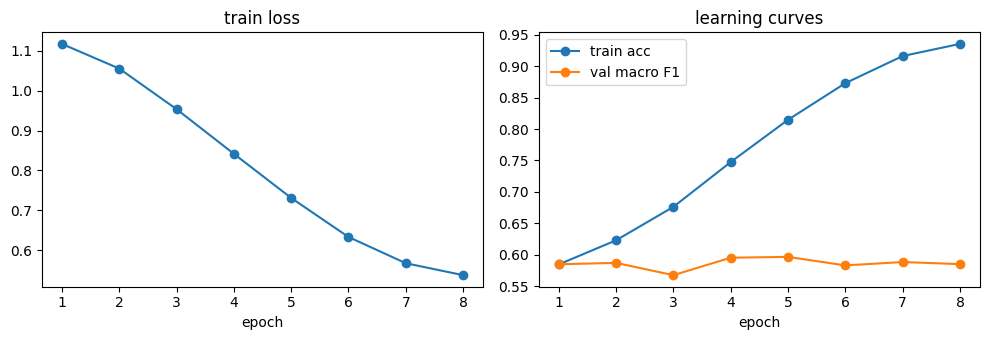

In [8]:
class CLIPEmotion(nn.Module):
    def __init__(self, visual, W, s):
        super().__init__()
        self.visual = visual
        self.head = nn.Parameter(W.clone())
        self.register_buffer("scale", torch.tensor(float(s)))
    def forward(self, x):
        return self.scale * F.normalize(self.visual(x).float(), dim=-1) @ F.normalize(self.head, dim=-1).T

net = CLIPEmotion(copy.deepcopy(model.visual), TEXT_W[BEST_PSET], scale).to(DEVICE)
ZS_STATE = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}   # zero-shot weights, for WiSE-FT
del model; torch.cuda.empty_cache() if AMP else None                            # text tower no longer needed

decay, no_decay = [], []
for n, p in net.visual.named_parameters():
    (decay if p.ndim >= 2 else no_decay).append(p)
opt = torch.optim.AdamW([{"params": decay, "lr": LR_BACKBONE, "weight_decay": WEIGHT_DECAY},
                         {"params": no_decay, "lr": LR_BACKBONE, "weight_decay": 0.0},
                         {"params": [net.head], "lr": LR_HEAD, "weight_decay": 0.0}])
sampler = None
if BALANCED_SAMPLER:
    w = (1.0 / tr.y.map(tr.y.value_counts())).values
    sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double), num_samples=len(tr), replacement=True)
train_dl = loader(tr, train_tf, shuffle=True, sampler=sampler)
total = EPOCHS * len(train_dl); warm = max(1, int(WARMUP_FRAC * total))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
crit = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE) if USE_CLASS_WEIGHTS else None, label_smoothing=LABEL_SMOOTH)
scaler = torch.amp.GradScaler(enabled=AMP)

@torch.no_grad()
def predict_probs(m, frame, tta=False):
    m.eval(); out = []
    for x, _ in loader(frame, eval_tf):
        x = x.to(DEVICE)
        with torch.autocast(DEVICE, enabled=AMP):
            p = m(x).float().softmax(-1)
            if tta: p = (p + m(torch.flip(x, dims=[3])).float().softmax(-1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()

hist, best_f1, best_state, bad = [], -1, None, 0
for ep in range(1, EPOCHS + 1):
    net.train(); t0 = time.time(); tl, tc, tn = 0.0, 0, 0
    for x, y in train_dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE, enabled=AMP):
            logits = net(x); loss = crit(logits.float(), y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        tl += loss.item() * len(y); tc += (logits.argmax(1) == y).sum().item(); tn += len(y)
    vm = metrics(va.y, predict_probs(net, va).argmax(1))
    hist.append({"epoch": ep, "train_loss": tl / tn, "train_acc": tc / tn, "val_acc": vm["accuracy"],
                 "val_macro_f1": vm["macro_f1"], "sec": time.time() - t0})
    print(f"epoch {ep}: loss {tl/tn:.3f} train_acc {tc/tn:.3f} | val acc {vm['accuracy']:.3f} macro-F1 {vm['macro_f1']:.3f} ({time.time()-t0:.0f}s)")
    if vm["macro_f1"] > best_f1:
        best_f1, bad = vm["macro_f1"], 0
        best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
    else:
        bad += 1
        if bad >= PATIENCE: print("early stop"); break
pd.DataFrame(hist).to_csv(OUT / "finetune_history.csv", index=False)
FT_STATE = best_state

h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h.epoch, h.train_loss, "o-"); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h.epoch, h.train_acc, "o-", label="train acc"); ax[1].plot(h.epoch, h.val_macro_f1, "o-", label="val macro F1")
ax[1].legend(); ax[1].set_xlabel("epoch"); ax[1].set_title("learning curves")
plt.tight_layout(); plt.savefig(OUT / "learning_curves.png", dpi=120); plt.show()

## 5 · WiSE-FT (robust fine-tuning) and flip TTA — both decided on val
`θ(α) = (1−α)·θ_zero-shot + α·θ_fine-tuned`. α = 0 is zero-shot CLIP, α = 1 is the fine-tuned model. Interpolating often keeps
CLIP's robustness (useful for real-world app photos: memes, odd lighting) while keeping most of the fine-tuning gain.

In [9]:
def interpolate(alpha):
    return {k: (1 - alpha) * ZS_STATE[k].float() + alpha * FT_STATE[k].float() if ZS_STATE[k].is_floating_point() else FT_STATE[k]
            for k in FT_STATE}

wise_rows = []
for a in [0.0, 0.25, 0.5, 0.75, 1.0]:
    net.load_state_dict(interpolate(a))
    wise_rows.append({"alpha": a, **metrics(va.y, predict_probs(net, va).argmax(1))})
wise = pd.DataFrame(wise_rows); print(wise.round(3).to_string(index=False))
BEST_ALPHA = wise.sort_values("macro_f1", ascending=False).alpha.iloc[0]
net.load_state_dict(interpolate(BEST_ALPHA))
f1_no = metrics(va.y, predict_probs(net, va).argmax(1))["macro_f1"]
f1_tta = metrics(va.y, predict_probs(net, va, tta=True).argmax(1))["macro_f1"]
USE_TTA = (f1_tta - f1_no) >= 0.002
print(f"→ alpha chosen on VAL: {BEST_ALPHA} | flip TTA val F1 {f1_no:.3f} → {f1_tta:.3f} → use TTA: {USE_TTA}")
wise.to_csv(OUT / "wise_ft_alpha_val.csv", index=False)

 alpha  accuracy  macro_f1  f1_angry  f1_happy  f1_relaxed  f1_sad
  0.00     0.565     0.543     0.424     0.695       0.452   0.600
  0.25     0.620     0.600     0.502     0.716       0.528   0.654
  0.50     0.646     0.625     0.525     0.727       0.576   0.672
  0.75     0.641     0.615     0.486     0.729       0.586   0.660
  1.00     0.626     0.597     0.456     0.713       0.573   0.646
→ alpha chosen on VAL: 0.5 | flip TTA val F1 0.625 → 0.623 → use TTA: False


## 6 · Final test evaluation (run once) and comparison with Part 2

                                   model          family  macro_f1  accuracy  f1_angry  f1_happy  f1_relaxed  f1_sad
                          Dummy (Part 2)        baseline     0.119     0.313       NaN       NaN         NaN     NaN
      ResNet-50 frozen + LogReg (Part 2) frozen features     0.414     0.440       NaN       NaN         NaN     NaN
           ResNet-50 fine-tuned (Part 2)      fine-tuned     0.558     0.579       NaN       NaN         NaN     NaN
            ViT-B/16 fine-tuned (Part 2)      fine-tuned     0.567     0.590       NaN       NaN         NaN     NaN
CLIP ViT-B-16 zero-shot (simple prompts)       zero-shot     0.538     0.560     0.423     0.679       0.445   0.605
   CLIP ViT-B-16 frozen + LogReg (C=3.0) frozen features     0.596     0.611     0.510     0.685       0.539   0.650
                CLIP ViT-B-16 fine-tuned      fine-tuned     0.594     0.616     0.478     0.675       0.573   0.651
CLIP ViT-B-16 fine-tuned + WiSE-FT α=0.5      fine-tuned     0.6

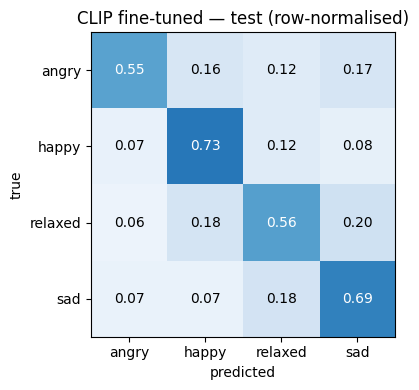

In [10]:
P_ft = predict_probs(net, te, tta=USE_TTA); pred = P_ft.argmax(1)
np.save(OUT / "probs_clip_finetuned_test.npy", P_ft)
net.load_state_dict(FT_STATE); m_ft_only = metrics(te.y, predict_probs(net, te, tta=USE_TTA).argmax(1))
net.load_state_dict(interpolate(BEST_ALPHA))

zs_best_test = zs[(zs.split == "test") & (zs.prompt_set == BEST_PSET)].iloc[0]
rows = [
    {"model": "Dummy (Part 2)", "family": "baseline", "macro_f1": 0.119, "accuracy": 0.313},
    {"model": "ResNet-50 frozen + LogReg (Part 2)", "family": "frozen features", "macro_f1": 0.414, "accuracy": 0.440},
    {"model": "ResNet-50 fine-tuned (Part 2)", "family": "fine-tuned", "macro_f1": 0.558, "accuracy": 0.579},
    {"model": "ViT-B/16 fine-tuned (Part 2)", "family": "fine-tuned", "macro_f1": 0.567, "accuracy": 0.590},
    {"model": f"CLIP {CLIP_ARCH} zero-shot ({BEST_PSET} prompts)", "family": "zero-shot", **{k: zs_best_test[k] for k in ["macro_f1", "accuracy"] + [f"f1_{l}" for l in LABELS]}},
    {"model": f"CLIP {CLIP_ARCH} frozen + LogReg (C={BEST_C})", "family": "frozen features", **probe_test},
    {"model": f"CLIP {CLIP_ARCH} fine-tuned", "family": "fine-tuned", **m_ft_only},
    {"model": f"CLIP {CLIP_ARCH} fine-tuned + WiSE-FT α={BEST_ALPHA}" + (" + TTA" if USE_TTA else ""), "family": "fine-tuned", **metrics(te.y, pred)},
]
final = pd.DataFrame(rows); final.to_csv(OUT / "final_comparison_test.csv", index=False)
print(final.round(3).to_string(index=False))
print("\n" + classification_report(te.y, pred, target_names=LABELS, digits=3))

cm = confusion_matrix(te.y, pred, normalize="true")
fig, ax = plt.subplots(figsize=(4.5, 4)); im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4), LABELS); ax.set_yticks(range(4), LABELS); ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(4):
    for j in range(4): ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > .5 else "black")
ax.set_title("CLIP fine-tuned — test (row-normalised)"); plt.tight_layout(); plt.savefig(OUT / "confusion_test.png", dpi=120); plt.show()

In [11]:
# ---------------- Export for the app + summary ----------------
ckpt = {"arch": CLIP_ARCH, "pretrained": CLIP_PRETRAINED, "labels": LABELS, "image_size": SIZE, "mean": list(MEAN), "std": list(STD),
        "state_dict": {k: (v.half() if v.is_floating_point() else v) for k, v in net.state_dict().items()},
        "wise_alpha": float(BEST_ALPHA), "tta": bool(USE_TTA), "prompt_set": BEST_PSET,
        "val_macro_f1": float(wise.macro_f1.max()), "test_macro_f1": float(metrics(te.y, pred)["macro_f1"]),
        "trained_on": "data/splits.csv train (clean YOLO crops), selected on val"}
torch.save(ckpt, OUT / "clip_emotion_ft.pt")
summary = {"config": {k: globals()[k] for k in ["CLIP_ARCH", "CLIP_PRETRAINED", "SEED", "EPOCHS", "BATCH", "LR_BACKBONE", "LR_HEAD",
           "WEIGHT_DECAY", "LABEL_SMOOTH", "USE_CLASS_WEIGHTS", "BALANCED_SAMPLER", "STRONG_AUG", "TEST"]},
           "decisions_on_val": {"prompt_set": BEST_PSET, "linear_probe_C": float(BEST_C), "wise_alpha": float(BEST_ALPHA), "tta": bool(USE_TTA)},
           "device": DEVICE, "results_test": final.to_dict(orient="records")}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1, default=float)
if not TEST:
    import shutil; shutil.make_archive(str(OUT.parent / "clip_finetune_results"), "zip", OUT)
print("saved to", OUT, "\n", sorted(p.name for p in OUT.iterdir()))

saved to /kaggle/working/mlproject/part3_multimodal/results/clip_finetune 
 ['clip_emotion_ft.pt', 'closed_set_check.json', 'confusion_test.png', 'final_comparison_test.csv', 'finetune_history.csv', 'learning_curves.png', 'linear_probe_C_sweep_val.csv', 'probs_clip_finetuned_test.npy', 'probs_linear_probe_test.npy', 'prompts.json', 'summary.json', 'wise_ft_alpha_val.csv', 'zeroshot_prompt_ablation.csv']


## Bring the results back to the repo
1. Download `clip_finetune_results.zip` (Kaggle: *Output* tab · Colab: Files panel).
2. Unzip it into `part3_multimodal/results/clip_finetune/` (CSV/JSON/PNG are committed).
3. Move **`clip_emotion_ft.pt`** to `part3_multimodal/artifacts/` (gitignored — too big for git).

**Do not** tune anything further on the test numbers above. Any new idea (balanced sampler, strong aug, ViT-L-14) is a new run,
decided on val, reported once on test.